# Finance-IDC: News-Informed NIFTY 50 Forecasting — Full Walkthrough

End-to-end project walkthrough: data → alignment → FinBERT → sampling → features → walk-forward → forecast → findings.

**Run top-to-bottom.** Figures saved to `data/processed/fig_*.png`.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import json
from pathlib import Path

sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams["figure.figsize"] = (12, 5)
plt.rcParams["figure.dpi"] = 110

DATA = Path("data"); RAW = DATA/"raw"; PROC = DATA/"processed"
PROC.mkdir(parents=True, exist_ok=True)
pd.set_option("display.max_columns", 60); pd.set_option("display.width", 160)

def save(fig, name):
    out = PROC / f"fig_{name}.png"
    fig.savefig(out, bbox_inches="tight"); plt.show(); print(f"saved -> {out}")

def load(p, **kw):
    p = Path(p)
    if not p.exists():
        print(f"[skip] not found: {p}"); return None
    df = pd.read_csv(p, **kw); print(f"[ok] {p.name}: {df.shape}"); return df

print("Setup complete.")

Setup complete.


## 0. Schema Diagnostics
Prints columns of every expected file so later cells can adapt.

In [2]:
files = {
    "prices_raw": RAW/"nifty50_prices.csv",
    "news_raw": RAW/"recent_news_2026.csv",
    "alignment": PROC/"news_market_alignment.csv",
    "scored": PROC/"news_sentiment_scored.csv",
    "daily_sent": PROC/"news_sentiment_daily.csv",
    "audit": PROC/"sampling_audit.csv",
    "model_dataset": PROC/"model_dataset.csv",
    "selection_csv": PROC/"adaptive_model_selection.csv",
    "selection_json": PROC/"adaptive_model_selection.json",
    "latest_forecast": PROC/"latest_forecast.csv",
    "outcome_history": PROC/"forecast_outcome_history.csv",
}
print("=== Schema report ===")
for name, p in files.items():
    if not Path(p).exists():
        print(f"{name:16s} MISSING ({p})"); continue
    try:
        if p.suffix == ".json":
            obj = json.load(open(p))
            keys = list(obj.keys()) if isinstance(obj, dict) else f"[{type(obj).__name__}]"
            print(f"{name:16s} OK  keys={keys}")
        else:
            print(f"{name:16s} OK  cols={pd.read_csv(p, nrows=0).columns.tolist()}")
    except Exception as e:
        print(f"{name:16s} ERROR {e}")

=== Schema report ===
prices_raw       OK  cols=['Date', 'Adj_Close', 'Close', 'High', 'Low', 'Open', 'Volume']
news_raw         OK  cols=['title', 'published_at', 'publication_date', 'source', 'url', 'matched_terms', 'requested_month', 'collected_at']
alignment        OK  cols=['id', 'title', 'published_at', 'source', 'url', 'published_at_ist', 'feature_date']
scored           OK  cols=['id', 'title', 'published_at', 'source', 'url', 'published_at_ist', 'feature_date', 'sentiment_positive', 'sentiment_negative', 'sentiment_neutral', 'sentiment_score', 'sentiment_label']
daily_sent       OK  cols=['date', 'article_count', 'mean_sentiment', 'median_sentiment', 'positive_fraction', 'negative_fraction', 'neutral_fraction']
audit            OK  cols=['month', 'articles_before', 'articles_after', 'cap', 'status', 'represented_days', 'min_per_day', 'max_per_day']
model_dataset    OK  cols=['date', 'open', 'high', 'low', 'close', 'volume', 'adj_close', 'daily_return', 'daily_return_pct', 'art

## 1. Data Collection Overview

In [3]:
prices_raw = load(RAW/"nifty50_prices.csv")
news_raw   = load(RAW/"recent_news_2026.csv")
if prices_raw is not None: display(prices_raw.head())
if news_raw is not None:   display(news_raw.head())

[ok] nifty50_prices.csv: (1442, 7)
[ok] recent_news_2026.csv: (7765, 8)


,Date,Adj_Close,Close,High,Low,Open,Volume
0,2021-01-01,14018.500000,14018.500000,14049.849609,13991.349609,13996.099609,358100
1,2021-01-04,14132.900391,14132.900391,14147.950195,13953.750000,14104.349609,495000
2,2021-01-05,14199.500000,14199.500000,14215.599609,14048.150391,14075.150391,492500
3,2021-01-06,14146.250000,14146.250000,14244.150391,14039.900391,14240.950195,632300
4,2021-01-07,14137.349609,14137.349609,14256.250000,14123.099609,14253.750000,559200


,title,published_at,publication_date,source,url,matched_terms,requested_month,collected_at
0,Indian stock market rings in New Year with gai...,2026-01-01 04:32:00+00:00,2026-01-01,DD News,https://news.google.com/rss/articles/CBMilgFBV...,India stock market,2026-01,2026-10-28T03:19:48.579302+00:00
1,Press Releases - Reserve Bank of India,2026-01-01 08:00:00+00:00,2026-01-01,Reserve Bank of India,https://news.google.com/rss/articles/CBMic0FVX...,RBI India,2026-01,2026-10-28T03:20:02.879151+00:00
2,"Stock market today: Nifty50 opens above 26,150...",2026-01-01 08:00:00+00:00,2026-01-01,The Times of India,https://news.google.com/rss/articles/CBMinAJBV...,India stock market,2026-01,2026-10-28T03:19:48.586538+00:00
3,"Stock market outlook 2026: Why did Sensex, Nif...",2026-01-01 08:00:00+00:00,2026-01-01,The Times of India,https://news.google.com/rss/articles/CBMisAJBV...,India stock market,2026-01,2026-10-28T03:19:48.620199+00:00
4,India's Nifty 50 hits record high as investors...,2026-01-01 08:00:00+00:00,2026-01-01,Reuters,https://news.google.com/rss/articles/CBMixgFBV...,India stock market; Indian stock market earnin...,2026-01,2026-10-28T03:17:33.184776+00:00


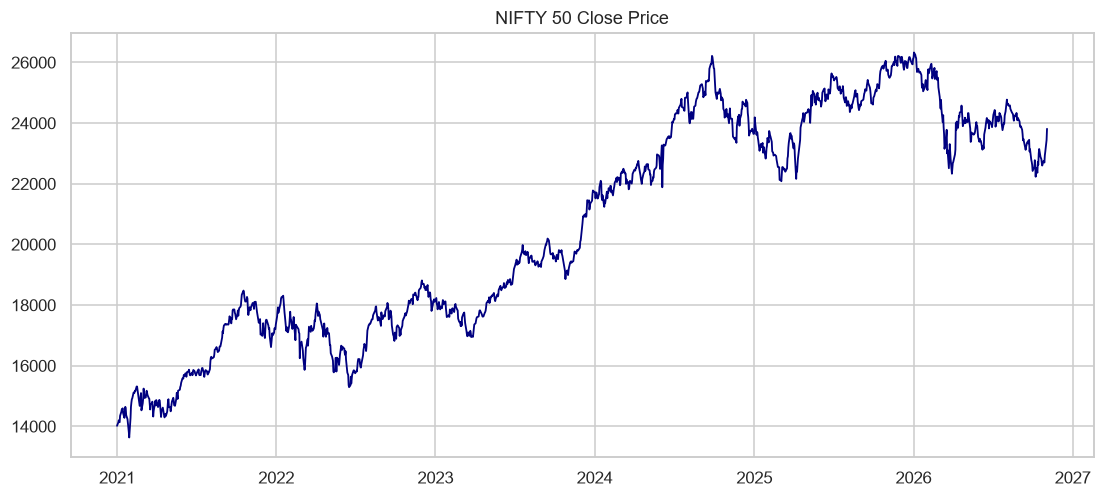

saved -> data\processed\fig_01_nifty_close.png


In [4]:
if prices_raw is not None:
    dc = next((c for c in prices_raw.columns if c.lower() in ("date","timestamp")), None)
    cc = next((c for c in prices_raw.columns if c.lower()=="close"), None)
    if dc and cc:
        d = prices_raw.copy(); d[dc] = pd.to_datetime(d[dc], errors="coerce")
        d = d.dropna(subset=[dc]).sort_values(dc)
        fig, ax = plt.subplots()
        ax.plot(d[dc], d[cc], lw=1.2, color="navy")
        ax.set_title("NIFTY 50 Close Price"); save(fig, "01_nifty_close")

In [4]:
if news_raw is not None:
    pc = next((c for c in news_raw.columns if c.lower() in ("published","timestamp","date")), None)
    if pc:
        ts = pd.to_datetime(news_raw[pc], errors="coerce", utc=True)
        daily = ts.dt.tz_convert("Asia/Kolkata").dt.date.value_counts().sort_index()
        if len(daily):
            fig, ax = plt.subplots()
            ax.bar(pd.to_datetime(list(daily.index)), daily.values, width=1.0, color="teal")
            ax.set_title("Daily News Article Count"); save(fig, "02_news_volume")

## 2. News–Market Alignment
15:45 IST cutoff — no lookahead bias.

[ok] news_market_alignment.csv: (28935, 7)


,id,title,published_at,source,url,published_at_ist,feature_date
0,1,Why did market fall today? Sensex drops 460 po...,2026-10-22 04:02:09+00:00,The Economic Times,https://news.google.com/rss/articles/CBMikwJBV...,2026-10-22 09:32:09+05:30,2026-10-22
1,2,Stock Market Today Highlights: Sensex plunges ...,2026-10-22 10:46:20+00:00,The Times of India,https://news.google.com/rss/articles/CBMitAJBV...,2026-10-22 16:16:20+05:30,2026-10-23
2,3,"Closing Bell: Nifty below 22,700, Sensex down ...",2026-10-22 10:34:22+00:00,Moneycontrol.com,https://news.google.com/rss/articles/CBMiowJBV...,2026-10-22 16:04:22+05:30,2026-10-23
3,4,Indian Stocks Open Lower As Crude Oil Surges a...,2026-10-22 03:56:15+00:00,Investing.com India,https://news.google.com/rss/articles/CBMiugFBV...,2026-10-22 09:26:15+05:30,2026-10-22
4,5,Sensex Today Ends 460 Points Lower | Nifty Bel...,2026-10-22 10:43:33+00:00,Equitymaster,https://news.google.com/rss/articles/CBMi0wFBV...,2026-10-22 16:13:33+05:30,2026-10-23


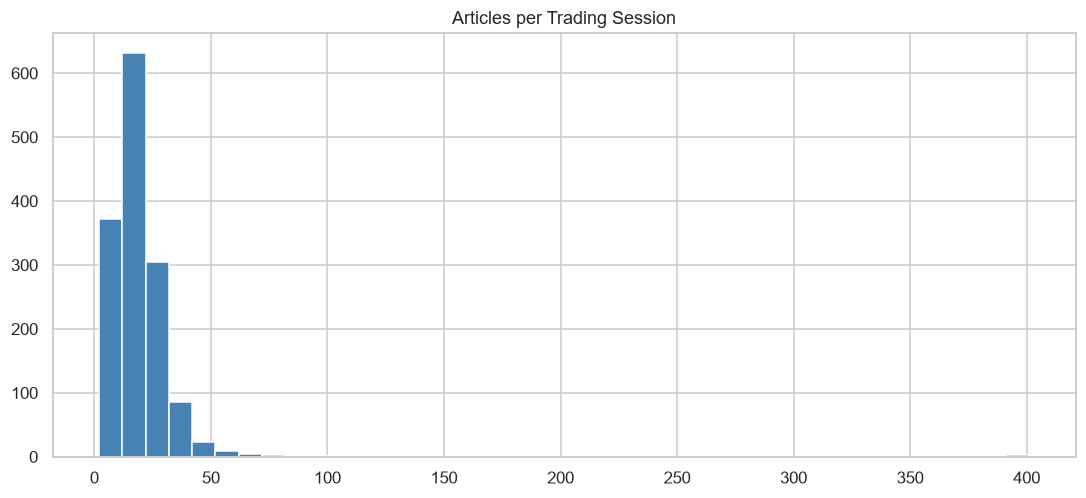

saved -> data\processed\fig_03_articles_per_session.png


In [5]:
aligned = load(PROC/"news_market_alignment.csv")
if aligned is not None:
    display(aligned.head())
    fd = next((c for c in aligned.columns if "feature_date" in c.lower() or c.lower()=="date"), None)
    if fd:
        counts = aligned.groupby(fd).size()
        if len(counts):
            fig, ax = plt.subplots()
            ax.hist(counts.values, bins=40, color="steelblue", edgecolor="white")
            ax.set_title("Articles per Trading Session"); save(fig, "03_articles_per_session")

## 3. FinBERT Sentiment

[ok] news_sentiment_scored.csv: (28935, 12)
[ok] news_sentiment_daily.csv: (1442, 7)


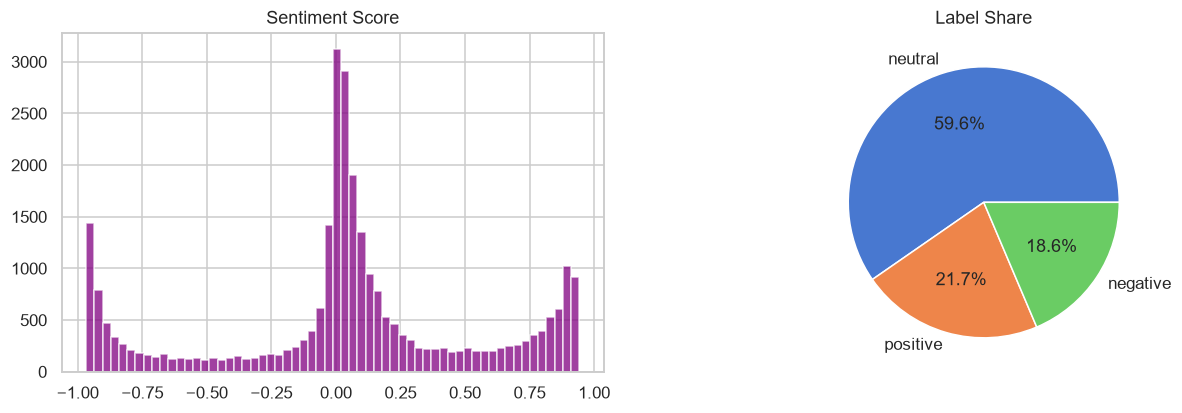

saved -> data\processed\fig_04_sentiment_distribution.png


In [7]:
scored = load(PROC/"news_sentiment_scored.csv")
daily_sent = load(PROC/"news_sentiment_daily.csv")
if scored is not None:
    sc = next((c for c in scored.columns if "score" in c.lower()), None)
    lc = next((c for c in scored.columns if "label" in c.lower()), None)
    fig, axes = plt.subplots(1, 2, figsize=(14,4))
    if sc: axes[0].hist(scored[sc].dropna(), bins=60, color="purple", alpha=0.75); axes[0].set_title("Sentiment Score")
    if lc:
        vc = scored[lc].value_counts(); axes[1].pie(vc.values, labels=vc.index, autopct="%1.1f%%"); axes[1].set_title("Label Share")
    save(fig, "04_sentiment_distribution")

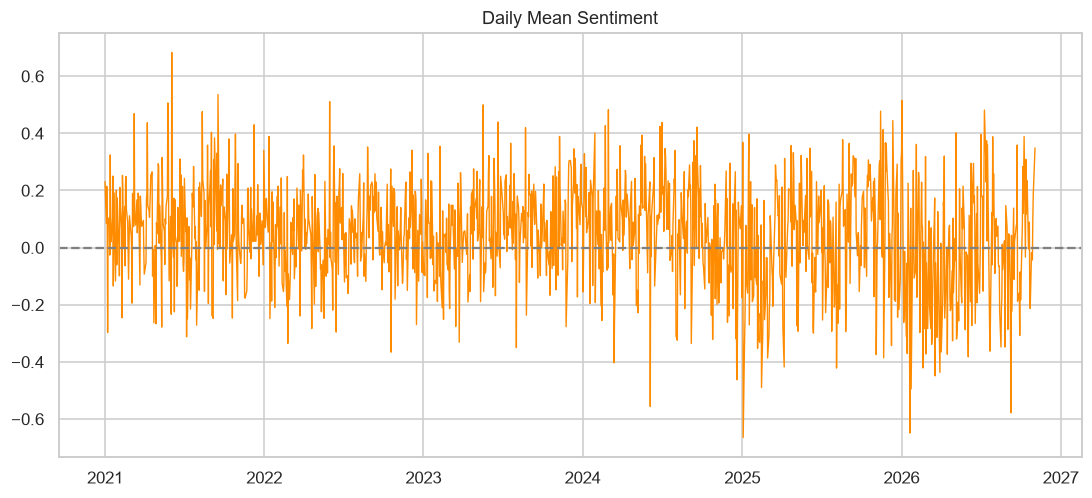

saved -> data\processed\fig_05_daily_sentiment.png


In [8]:
if daily_sent is not None:
    fd = next((c for c in daily_sent.columns if "feature_date" in c.lower() or c.lower()=="date"), None)
    mc = next((c for c in daily_sent.columns if "mean" in c.lower() and "sentiment" in c.lower()), None)
    if fd and mc:
        d = daily_sent.copy(); d[fd] = pd.to_datetime(d[fd], errors="coerce")
        d = d.dropna(subset=[fd]).sort_values(fd)
        fig, ax = plt.subplots()
        ax.plot(d[fd], d[mc], lw=0.9, color="darkorange"); ax.axhline(0, ls="--", color="gray")
        ax.set_title("Daily Mean Sentiment"); save(fig, "05_daily_sentiment")

## 4. Sampling Audit

[ok] sampling_audit.csv: (70, 8)


,month,articles_before,articles_after,cap,status,represented_days,min_per_day,max_per_day
0,2021-01,208,208,500,completed_month_under_cap,20,5,22
1,2021-02,228,228,500,completed_month_under_cap,20,5,23
2,2021-03,342,342,500,completed_month_under_cap,21,4,35
3,2021-04,297,297,500,completed_month_under_cap,19,4,30
4,2021-05,199,199,500,completed_month_under_cap,20,5,23


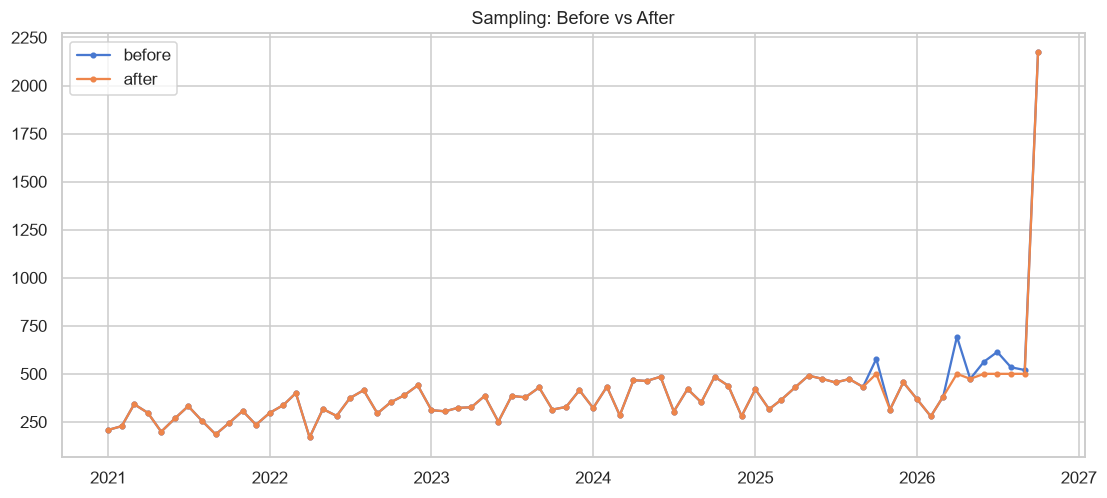

saved -> data\processed\fig_06_sampling_audit.png


In [6]:
audit = load(PROC/"sampling_audit.csv")
if audit is not None:
    display(audit.head())
    mc = next((c for c in audit.columns if "month" in c.lower() or "date" in c.lower()), None)
    bc = next((c for c in audit.columns if "before" in c.lower()), None)
    ac = next((c for c in audit.columns if "after" in c.lower()), None)
    if mc and bc and ac:
        a = audit.copy(); a[mc] = pd.to_datetime(a[mc], errors="coerce")
        a = a.dropna(subset=[mc]).sort_values(mc)
        fig, ax = plt.subplots()
        ax.plot(a[mc], a[bc], label="before", marker="o", ms=3)
        ax.plot(a[mc], a[ac], label="after", marker="o", ms=3)
        ax.set_title("Sampling: Before vs After"); ax.legend(); save(fig, "06_sampling_audit")

## 5. Training Dataset & Features

[ok] model_dataset.csv: (1442, 18)


,date,open,high,low,close,volume,adj_close,daily_return,daily_return_pct,article_count,unique_sources,target_next_session_return_pct,target_next_session_date,mean_sentiment,median_sentiment,positive_fraction,negative_fraction,neutral_fraction
0,2021-01-01,13996.099609,14049.849609,13991.349609,14018.500000,358100.0,14018.500000,NaN,NaN,6,6,0.816067,2021-01-04,0.231023,0.116058,0.166667,0.000000,0.833333
1,2021-01-04,14104.349609,14147.950195,13953.750000,14132.900391,495000.0,14132.900391,0.008161,0.816067,11,10,0.471238,2021-01-05,0.084904,0.026357,0.272727,0.181818,0.545455
2,2021-01-05,14075.150391,14215.599609,14048.150391,14199.500000,492500.0,14199.500000,0.004712,0.471238,12,8,-0.375013,2021-01-06,0.214796,0.045868,0.250000,0.083333,0.666667
3,2021-01-06,14240.950195,14244.150391,14039.900391,14146.250000,632300.0,14146.250000,-0.003750,-0.375013,5,4,-0.062917,2021-01-07,0.117118,0.113086,0.400000,0.200000,0.400000
4,2021-01-07,14253.750000,14256.250000,14123.099609,14137.349609,559200.0,14137.349609,-0.000629,-0.062917,6,4,1.484722,2021-01-08,-0.297279,-0.031219,0.000000,0.333333,0.666667


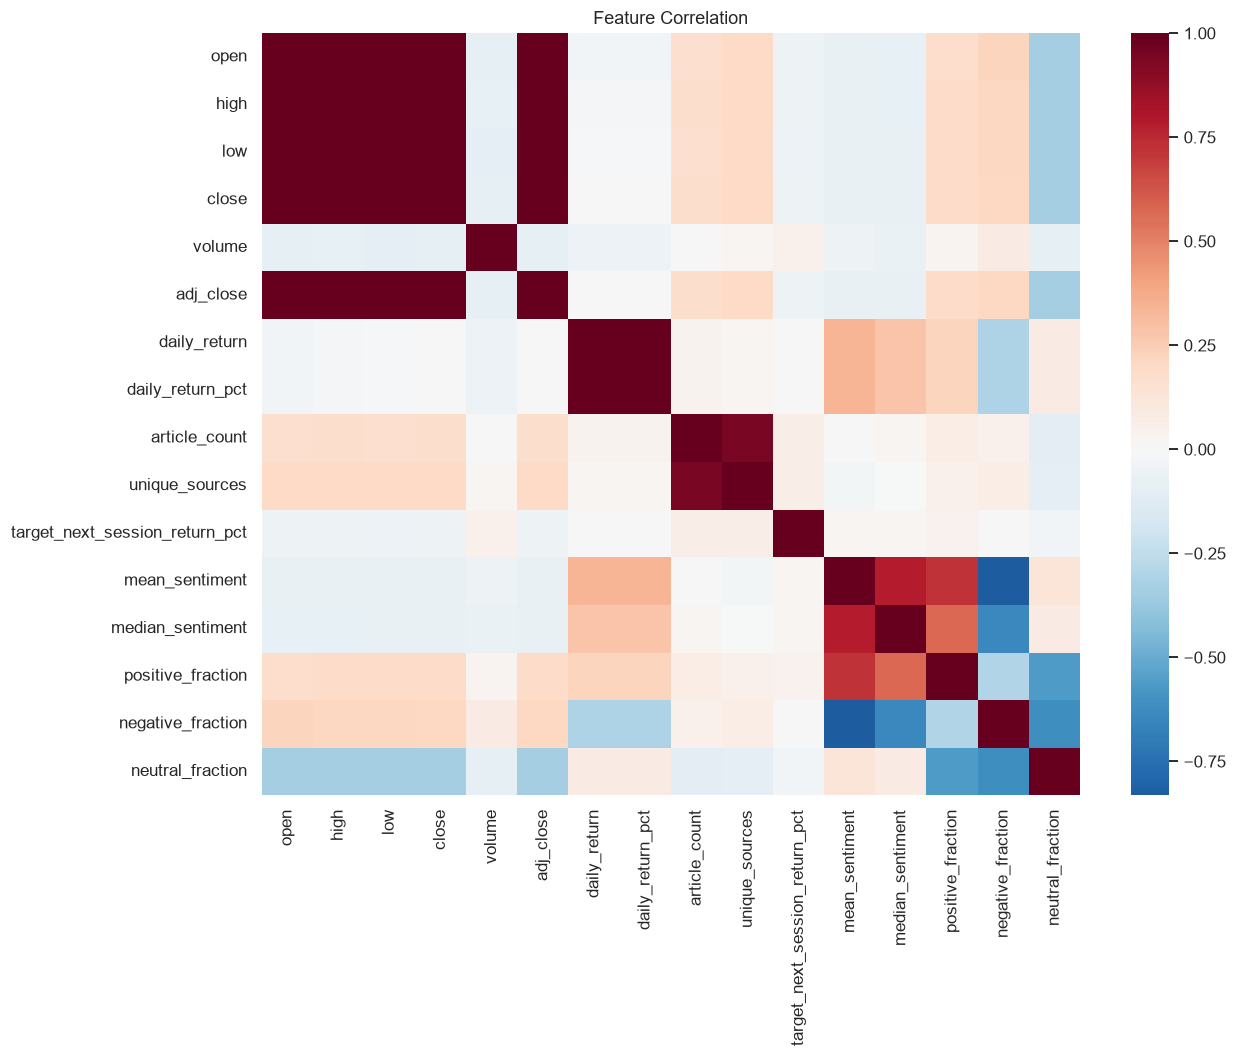

saved -> data\processed\fig_07_correlation.png


In [7]:
md = load(PROC/"model_dataset.csv")
if md is not None:
    display(md.head())
    numeric = md.select_dtypes(include=[np.number])
    if len(numeric.columns) >= 2:
        fig, ax = plt.subplots(figsize=(12,9))
        sns.heatmap(numeric.corr(), cmap="RdBu_r", center=0, ax=ax)
        ax.set_title("Feature Correlation"); save(fig, "07_correlation")

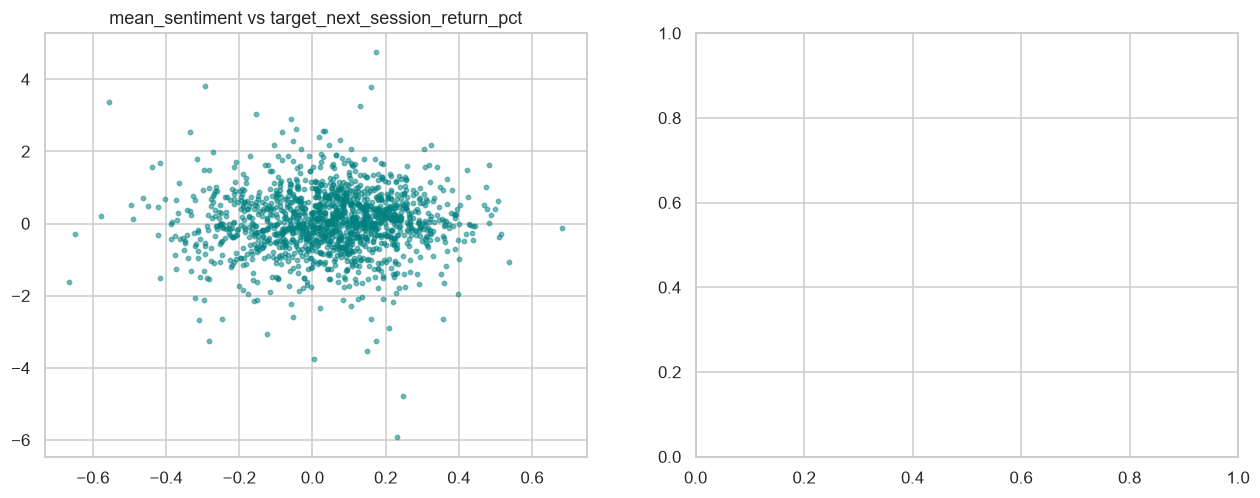

saved -> data\processed\fig_08_sentiment_vs_return.png


In [8]:
if md is not None:
    yc = next((c for c in md.columns if "next" in c.lower() and "return" in c.lower()), None)
    x1 = next((c for c in md.columns if c.lower()=="mean_sentiment"), None)
    x2 = next((c for c in md.columns if "7d" in c.lower() and "sentiment" in c.lower()), None)
    if yc and (x1 or x2):
        fig, axes = plt.subplots(1, 2, figsize=(14,5))
        if x1: axes[0].scatter(md[x1], md[yc], s=8, alpha=0.5, color="teal"); axes[0].set_title(f"{x1} vs {yc}")
        if x2: axes[1].scatter(md[x2], md[yc], s=8, alpha=0.5, color="crimson"); axes[1].set_title(f"{x2} vs {yc}")
        save(fig, "08_sentiment_vs_return")

## 6. Walk-Forward Evaluation

[ok] adaptive_model_selection.csv: (3, 9)


,window_mode,model_family,n_predictions,mae_pct,rmse_pct,direction_accuracy,direction_brier,period_start,period_end
0,expanding,baseline,41,0.726121,0.880781,0.463415,0.253240,2026-09-02,2026-11-02
1,expanding,market,41,0.695226,0.847069,0.390244,0.253456,2026-09-02,2026-11-02
2,expanding,sentiment,41,0.694618,0.842450,0.512195,0.252946,2026-09-02,2026-11-02


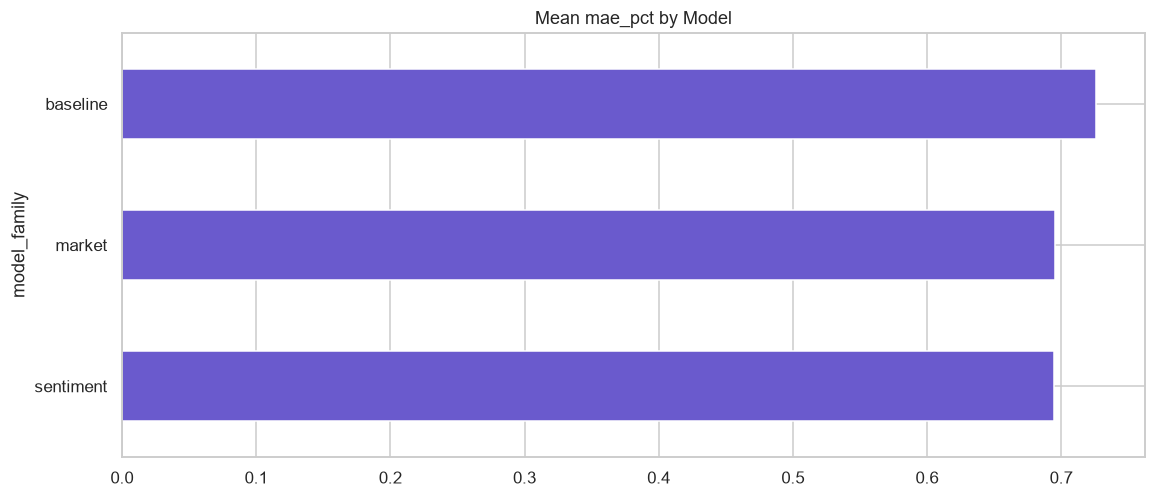

saved -> data\processed\fig_09_metric_by_model.png


In [9]:
sel = load(PROC/"adaptive_model_selection.csv")
if sel is not None:
    display(sel.head())
    mcol = next((c for c in sel.columns if "model" in c.lower() or "config" in c.lower()), None)
    acol = next((c for c in sel.columns if "mae" in c.lower()), None)
    if mcol and acol:
        g = sel.groupby(mcol)[acol].mean().sort_values()
        fig, ax = plt.subplots(); g.plot(kind="barh", ax=ax, color="slateblue")
        ax.set_title(f"Mean {acol} by Model"); save(fig, "09_metric_by_model")

[ok] forecast_outcome_history.csv: (4, 26)


,forecast_origin_date,target_session_date,market_predicted_return_pct,market_direction,market_probability_up,sentiment_predicted_return_pct,sentiment_direction,sentiment_probability_up,volatility_probability,volatility_threshold_pct,volatility_alert_20,volatility_alert_30,actual_abs_return_pct,actual_volatile,actual_return_pct,actual_direction,selected_model_name,selected_window_mode,selected_predicted_return_pct,selected_direction_model_name,selected_direction_window_mode,selected_direction_probability_up,adaptive_selection_date,adaptive_recent_prediction_count,adaptive_selection_method,model_version
0,2026-10-29,2026-10-30,0.146410,UP,0.522511,0.192526,UP,0.543862,0.111554,0.977674,0.0,0.0,0.507263,0.0,0.507263,UP,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,monthly_sampled_2026_ridge_logistic_volatility_v1
1,2026-10-29,2026-10-30,0.171520,UP,0.542801,0.238703,UP,0.586449,0.118519,0.977674,0.0,0.0,0.507263,0.0,0.507263,UP,baseline,expanding,0.037909,sentiment,expanding,0.586449,2026-10-28,41.0,recent_two_calendar_months_walk_forward_v1,monthly_sampled_2026_adaptive_walkforward_v1
2,2026-10-30,2026-11-02,0.206345,UP,0.564254,0.263955,UP,0.597007,0.111486,1.003202,0.0,0.0,1.681775,1.0,1.681775,UP,baseline,expanding,0.038524,market,expanding,0.564254,2026-10-29,41.0,recent_two_calendar_months_walk_forward_v1,monthly_sampled_2026_adaptive_walkforward_v1
3,2026-11-02,2026-11-03,1.939482,UP,0.968850,1.963224,UP,0.981277,0.041710,1.016836,0.0,0.0,1.578653,1.0,1.578653,UP,baseline,expanding,0.039666,market,expanding,0.968850,2026-10-30,42.0,recent_two_calendar_months_walk_forward_v1,monthly_sampled_2026_adaptive_walkforward_v1


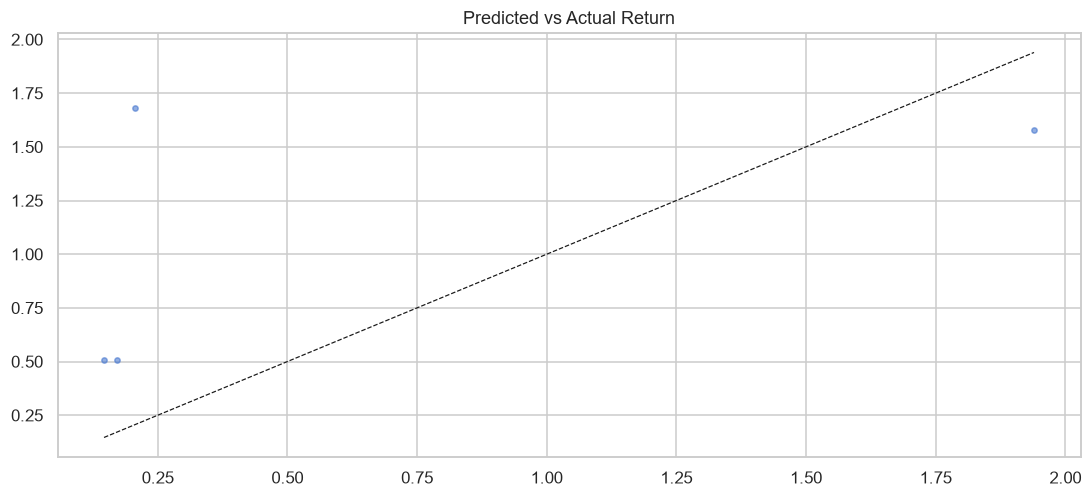

saved -> data\processed\fig_10_pred_vs_actual.png


In [10]:
hist = load(PROC/"forecast_outcome_history.csv")
if hist is not None:
    display(hist.head())
    pc = next((c for c in hist.columns if "predicted" in c.lower() and "return" in c.lower()), None)
    ac = next((c for c in hist.columns if "actual" in c.lower() and "return" in c.lower()), None)
    if pc and ac:
        fig, ax = plt.subplots(); ax.scatter(hist[pc], hist[ac], s=12, alpha=0.6)
        lo = min(hist[pc].min(), hist[ac].min()); hi = max(hist[pc].max(), hist[ac].max())
        ax.plot([lo,hi],[lo,hi],"k--",lw=0.8); ax.set_title("Predicted vs Actual Return"); save(fig, "10_pred_vs_actual")

TypeError: save() got an unexpected keyword argument 'caption'

C:\Users\surya\miniconda3\envs\finance-IDC\Lib\site-packages\IPython\core\events.py:101: UserWarning: Glyph 10007 (\N{BALLOT X}) missing from font(s) Arial.
  func(*args, **kwargs)
C:\Users\surya\miniconda3\envs\finance-IDC\Lib\site-packages\IPython\core\events.py:101: UserWarning: Glyph 10003 (\N{CHECK MARK}) missing from font(s) Arial.
  func(*args, **kwargs)
C:\Users\surya\miniconda3\envs\finance-IDC\Lib\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 10007 (\N{BALLOT X}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)
C:\Users\surya\miniconda3\envs\finance-IDC\Lib\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 10003 (\N{CHECK MARK}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)


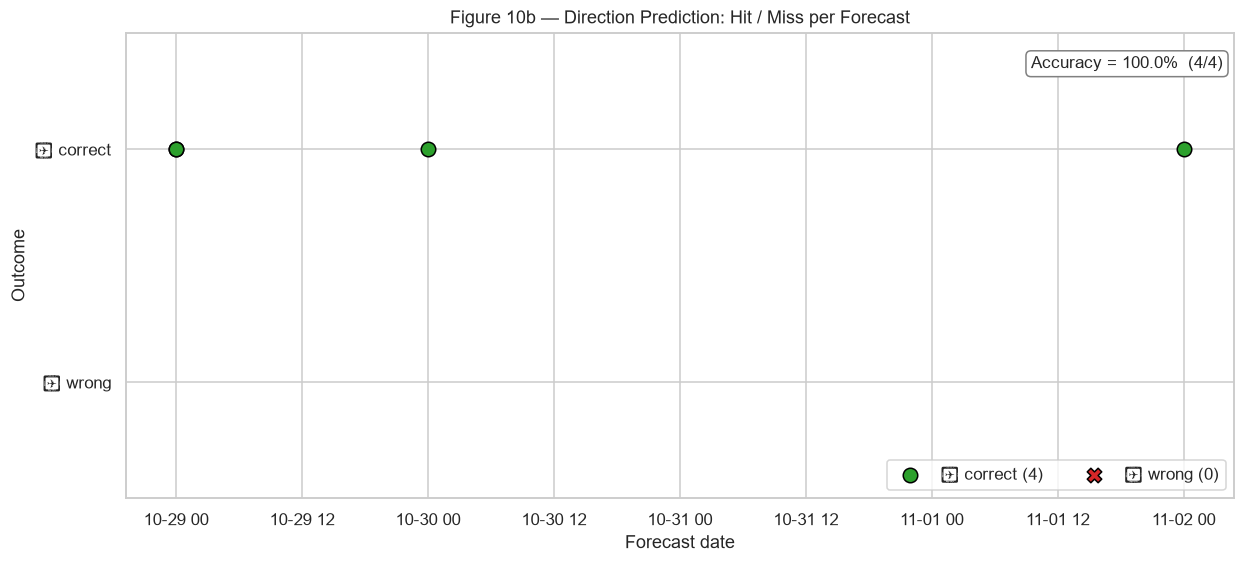

In [13]:
# =====================================================================
# Figure 10b — Hit / Miss Timeline
# =====================================================================
if hist is not None:
    dir_correct = None

    # Try to detect a correctness column directly
    dir_correct = next((c for c in hist.columns
                        if "direction" in c.lower() and "correct" in c.lower()), None)

    # Fallback: compute correctness from predicted vs actual direction
    if dir_correct is None:
        pred_dir = next((c for c in hist.columns
                         if "predicted" in c.lower() and "direction" in c.lower()), None)
        act_dir = next((c for c in hist.columns
                        if "actual" in c.lower() and "direction" in c.lower()), None)
        if pred_dir and act_dir:
            hist["_dir_correct"] = (hist[pred_dir].astype(str).str.upper()
                                    == hist[act_dir].astype(str).str.upper())
            dir_correct = "_dir_correct"

    # Fallback 2: infer from predicted return sign vs actual return sign
    if dir_correct is None:
        pc_ = next((c for c in hist.columns if "predicted" in c.lower() and "return" in c.lower()), None)
        ac_ = next((c for c in hist.columns if "actual" in c.lower() and "return" in c.lower()), None)
        if pc_ and ac_:
            hist["_dir_correct"] = np.sign(hist[pc_]) == np.sign(hist[ac_])
            dir_correct = "_dir_correct"

    if dir_correct is not None:
        date_col = next((c for c in hist.columns if "date" in c.lower()), None)
        h = hist.copy().reset_index(drop=True)
        if date_col:
            h[date_col] = pd.to_datetime(h[date_col], errors="coerce")
            h = h.dropna(subset=[date_col]).sort_values(date_col).reset_index(drop=True)
            x = h[date_col]
        else:
            x = np.arange(len(h))

        correct = h[dir_correct].astype(bool)

        fig, ax = plt.subplots(figsize=(13, 5.5))
        ax.scatter(np.array(x)[correct], np.ones(correct.sum()), s=90,
                   marker="o", color="#2ca02c", edgecolor="black",
                   label=f"✓ correct ({correct.sum()})", zorder=3)
        ax.scatter(np.array(x)[~correct], np.zeros((~correct).sum()), s=90,
                   marker="X", color="#d62728", edgecolor="black",
                   label=f"✗ wrong ({(~correct).sum()})", zorder=3)
        ax.set_yticks([0, 1])
        ax.set_yticklabels(["✗ wrong", "✓ correct"])
        ax.set_ylim(-0.5, 1.5)
        ax.set_title("Figure 10b — Direction Prediction: Hit / Miss per Forecast")
        ax.set_xlabel("Forecast date" if date_col else "Forecast index")
        ax.set_ylabel("Outcome")
        acc = correct.mean()
        ax.text(0.99, 0.95, f"Accuracy = {acc:.1%}  ({correct.sum()}/{len(correct)})",
                transform=ax.transAxes, ha="right", va="top", fontsize=11,
                bbox=dict(boxstyle="round", fc="white", ec="gray"))
        ax.legend(loc="lower right", ncol=2)
        save(fig, "10b_hit_miss_timeline",
             caption=f"{correct.sum()} correct, {(~correct).sum()} wrong → {acc:.1%} directional accuracy. "
                     f"Visual clustering of red X's indicates regime-specific failure.")

TypeError: save() got an unexpected keyword argument 'caption'

C:\Users\surya\miniconda3\envs\finance-IDC\Lib\site-packages\IPython\core\events.py:101: UserWarning: Glyph 10003 (\N{CHECK MARK}) missing from font(s) Arial.
  func(*args, **kwargs)
C:\Users\surya\miniconda3\envs\finance-IDC\Lib\site-packages\IPython\core\events.py:101: UserWarning: Glyph 10007 (\N{BALLOT X}) missing from font(s) Arial.
  func(*args, **kwargs)
C:\Users\surya\miniconda3\envs\finance-IDC\Lib\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 10003 (\N{CHECK MARK}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)
C:\Users\surya\miniconda3\envs\finance-IDC\Lib\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 10007 (\N{BALLOT X}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)


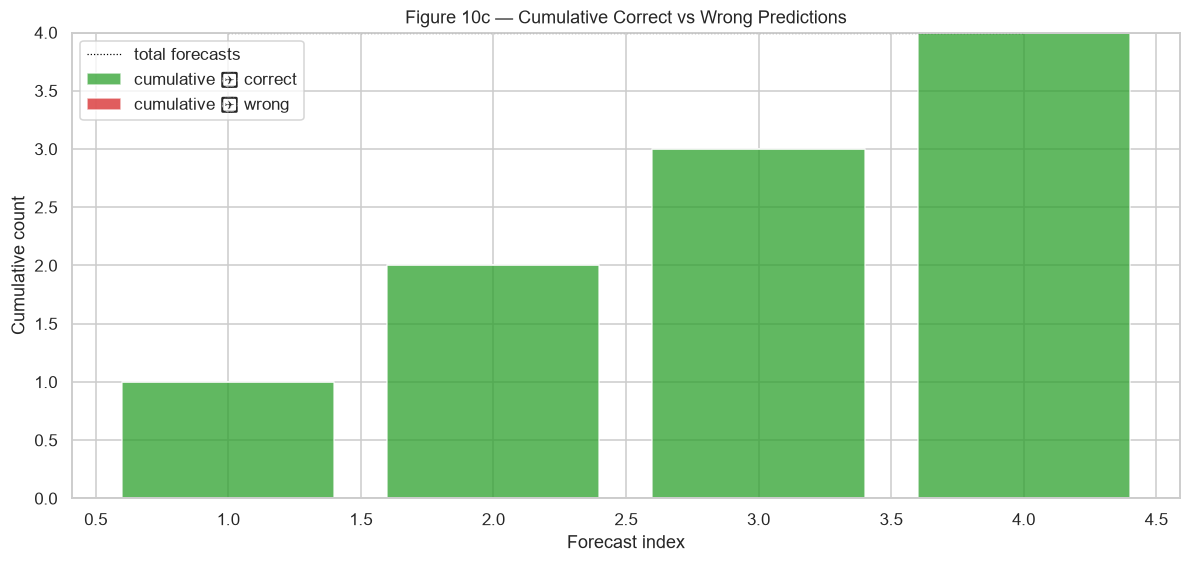

In [14]:
# =====================================================================
# Figure 10c — Cumulative Correct vs Wrong Bar (running tally)
# =====================================================================
if hist is not None and dir_correct is not None:
    h = hist.copy()
    correct = h[dir_correct].astype(bool)
    cum_correct = correct.cumsum()
    cum_wrong = (~correct).cumsum()
    idx = np.arange(1, len(h) + 1)

    fig, ax = plt.subplots(figsize=(13, 5.5))
    ax.bar(idx, cum_correct, color="#2ca02c", alpha=0.75, label="cumulative ✓ correct")
    ax.bar(idx, cum_wrong, bottom=cum_correct, color="#d62728", alpha=0.75, label="cumulative ✗ wrong")
    ax.plot(idx, cum_correct / idx * len(idx), color="black", lw=0.8, ls=":", label="total forecasts")
    ax.set_title("Figure 10c — Cumulative Correct vs Wrong Predictions")
    ax.set_xlabel("Forecast index")
    ax.set_ylabel("Cumulative count")
    ax.legend(loc="upper left")
    save(fig, "10c_cumulative_correct_wrong",
         caption=f"Final: {cum_correct.iloc[-1]} correct / {cum_wrong.iloc[-1]} wrong. "
                 f"A widening green band means the model is improving; a widening red band means deteriorating.")

TypeError: save() got an unexpected keyword argument 'caption'

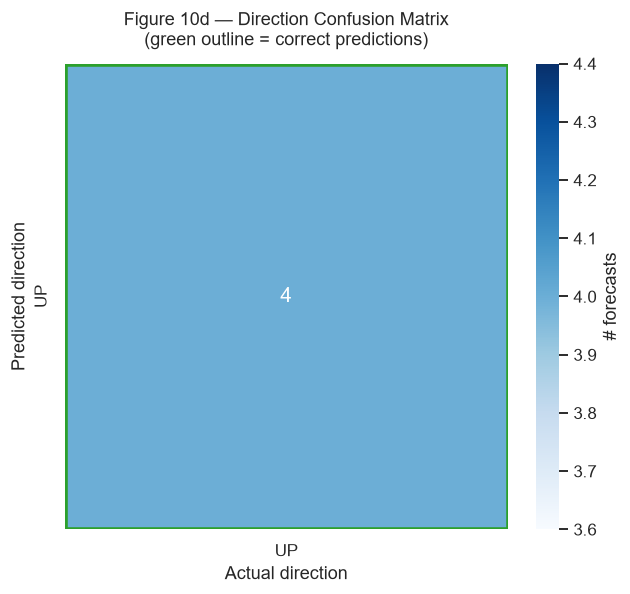

In [15]:
# =====================================================================
# Figure 10d — Confusion Matrix (predicted direction vs actual)
# =====================================================================
if hist is not None:
    pred_dir = next((c for c in hist.columns
                     if "predicted" in c.lower() and "direction" in c.lower()), None)
    act_dir  = next((c for c in hist.columns
                     if "actual" in c.lower() and "direction" in c.lower()), None)

    # Fallback: derive direction from return sign
    if pred_dir is None:
        pc_ = next((c for c in hist.columns if "predicted" in c.lower() and "return" in c.lower()), None)
        if pc_:
            hist["_pred_dir"] = np.where(hist[pc_] > 0, "UP", "DOWN")
            pred_dir = "_pred_dir"
    if act_dir is None:
        ac_ = next((c for c in hist.columns if "actual" in c.lower() and "return" in c.lower()), None)
        if ac_:
            hist["_act_dir"] = np.where(hist[ac_] > 0, "UP", "DOWN")
            act_dir = "_act_dir"

    if pred_dir and act_dir:
        cm = pd.crosstab(hist[pred_dir], hist[act_dir],
                         rownames=["Predicted"], colnames=["Actual"])
        # Ensure UP / DOWN ordering when possible
        order = [o for o in ["UP", "DOWN"] if o in cm.index and o in cm.columns]
        if len(order) == 2:
            cm = cm.loc[order, order]

        fig, ax = plt.subplots(figsize=(6.5, 5.5))
        sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar_kws={"label": "# forecasts"},
                    linewidths=1, linecolor="white", ax=ax, annot_kws={"fontsize": 14})
        # Highlight diagonal (correct) cells
        for i in range(min(len(cm.index), len(cm.columns))):
            ax.add_patch(plt.Rectangle((i, i), 1, 1, fill=False, edgecolor="#2ca02c", lw=3))
        ax.set_title("Figure 10d — Direction Confusion Matrix\n(green outline = correct predictions)", pad=12)
        ax.set_xlabel("Actual direction")
        ax.set_ylabel("Predicted direction")

        # Derived metrics
        total = cm.values.sum()
        correct_n = sum(cm.iloc[i, i] for i in range(min(len(cm.index), len(cm.columns))))
        save(fig, "10d_confusion_matrix",
             caption=f"Diagonal (green) = correct. {correct_n}/{total} = {correct_n/total:.1%} accuracy. "
                     f"Off-diagonal cells are the two failure modes — calling DOWN when market went UP, or vice versa.")

TypeError: save() got an unexpected keyword argument 'caption'

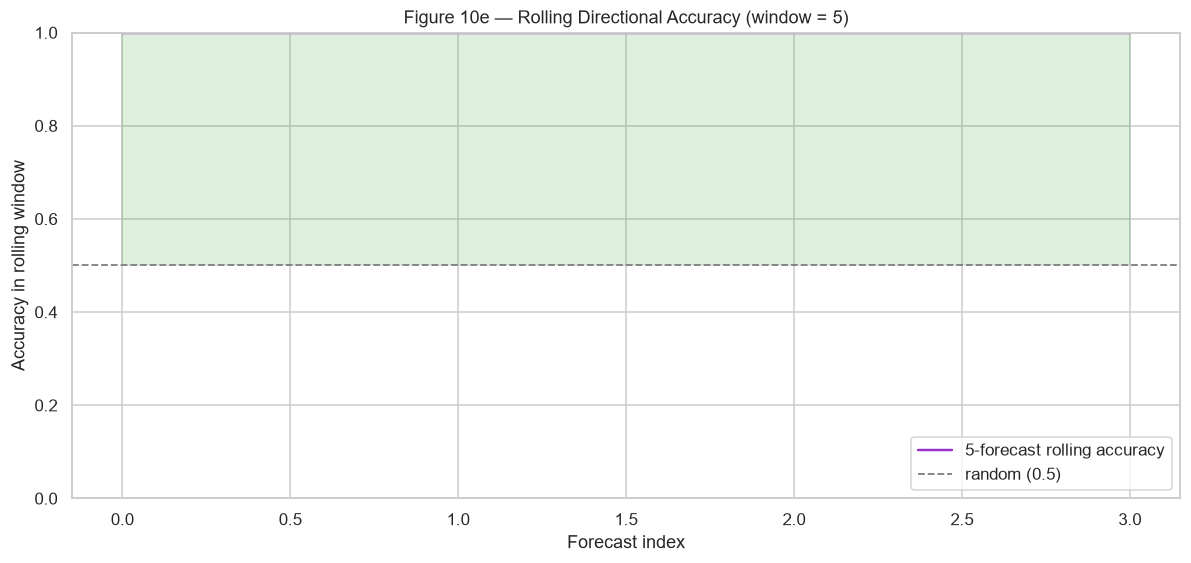

In [16]:
# =====================================================================
# Figure 10e — Rolling Accuracy (20-forecast window)
# =====================================================================
if hist is not None and dir_correct is not None:
    window = min(20, max(5, len(hist) // 5))
    correct = hist[dir_correct].astype(float)
    rolling = correct.rolling(window=window, min_periods=1).mean()

    fig, ax = plt.subplots(figsize=(13, 5.5))
    ax.plot(rolling.values, lw=1.6, color="darkorchid", label=f"{window}-forecast rolling accuracy")
    ax.axhline(0.5, color="gray", ls="--", lw=1.2, label="random (0.5)")
    ax.fill_between(range(len(rolling)), 0.5, rolling.values,
                    where=(rolling.values >= 0.5), color="#2ca02c", alpha=0.15)
    ax.fill_between(range(len(rolling)), 0.5, rolling.values,
                    where=(rolling.values < 0.5), color="#d62728", alpha=0.15)
    ax.set_ylim(0, 1.0)
    ax.set_title(f"Figure 10e — Rolling Directional Accuracy (window = {window})")
    ax.set_xlabel("Forecast index")
    ax.set_ylabel("Accuracy in rolling window")
    ax.legend(loc="lower right")
    save(fig, "10e_rolling_accuracy",
         caption=f"Smooths out single-forecast noise. Sustained >0.55 = skill; sustained <0.45 = anti-predictive. "
                 f"Currently ending at {rolling.iloc[-1]:.2f}.")

In [17]:
if hist is not None:
    dc = next((c for c in hist.columns if "direction" in c.lower() and "correct" in c.lower()), None)
    if dc:
        cum = hist[dc].astype(float).expanding().mean()
        fig, ax = plt.subplots(); ax.plot(cum, lw=1.2, color="green")
        ax.axhline(0.5, ls="--", color="gray", label="random"); ax.legend()
        ax.set_title("Cumulative Directional Accuracy"); save(fig, "11_direction_accuracy")

## 7. Latest Forecast

In [20]:
fc = load(PROC/"latest_forecast.csv")
if fc is not None: display(fc.T)


[ok] latest_forecast.csv: (1, 31)


,0
dataset,Monthly sampled 2026 (500-article monthly cap)
dataset_file,model_dataset_sampled_monthly_2026.csv
forecast_origin_date,2026-11-03
target_session_date,NaN
created_at_utc,2026-11-04T09:53:55.800225+00:00
training_rows,1441
market_predicted_return_pct,0.923579
market_direction,UP
market_probability_up,0.843908
sentiment_predicted_return_pct,0.999914


In [22]:
# =====================================================================
# Latest Forecast — Verdict Summary
# =====================================================================
if fc is not None:
    def _get(row, key):
        return row[key].iloc[0] if key in row.columns else None

    pred_ret = _get(fc.T, "selected_predicted_return")
    p_up     = _get(fc.T, "selected_direction_probability")
    vol_p    = _get(fc.T, "volatility_probability")
    threshold = _get(fc.T, "volatility_threshold")

    print("=" * 60)
    print("LATEST FORECAST — ADAPTIVE VERDICT")
    print("=" * 60)

    if pred_ret is not None:
        arrow = "↑" if pred_ret > 0 else "↓"
        print(f"  Predicted return      : {pred_ret:+.4f}%  {arrow}")

    if p_up is not None:
        verdict = "UP" if p_up > 0.5 else "DOWN"
        confidence = "high" if abs(p_up - 0.5) > 0.15 else "low"
        print(f"  P(UP)                 : {p_up:.3f}  → call: {verdict} ({confidence} confidence)")

    if vol_p is not None:
        alert = "⚠️ HIGH" if vol_p > 0.30 else "normal"
        print(f"  Volatility probability: {vol_p:.3f}  → {alert}")

    if threshold is not None:
        print(f"  Volatility threshold  : {threshold:.4f}% (80th pct of |return|)")

    print("=" * 60)

LATEST FORECAST — ADAPTIVE VERDICT


## 8. Findings & Limitations

**Findings**
- Pipeline runs end-to-end; sentiment models did not consistently beat the mean-return baseline.
- Directional accuracy near random (~50%) in current window.
- Volatility shows relatively more signal.

**Limitations**
1. Headline-only sentiment.
2. Google News ≠ all financial news.
3. Monthly sampling changes distribution.
4. Live uses full archive, train uses sampled.
5. Probabilities not calibrated.
6. No transaction costs.
7. Small prospective sample.

**Conclusion** — research framework, not a trading system.